# NASA C-MAPSS FD001 — Temporal Convolutional Network (TCN) for RUL Prediction

This experiment replaces the BiLSTM/CNN-BiLSTM with a **causal dilated Temporal Convolutional Network (TCN)**.

The data split, RUL cap, feature selection, window generation, validation cutoffs, and evaluation metrics follow the audited V3 pipeline so the model comparison is controlled.

**Important:** this notebook has fresh outputs removed. Run it from top to bottom. Do not compare its validation score with V2's 20-point validation set; this notebook uses multiple cutoffs per held-out engine.


In [1]:
import copy
import random
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline

import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = device.type == "cuda"

print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.13.0+cpu
Device: cpu


## 2. Configuration and dataset loading

Update `DATA_DIR` to the folder containing the three FD001 files. The notebook can be run in Colab or local Jupyter.

In [2]:
# Colab example:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = Path("/content/drive/MyDrive/CMaps")

# Local Windows example — CHANGE THIS PATH:
DATA_DIR = Path(r"D:\ML_project\extracted\CMaps")

SUBSET = "FD001"  # FD001, FD002, FD003, FD004

RUL_CAP = 125
WINDOW_SIZE = 30
VAL_SIZE = 0.20

# Multiple validation RUL points per held-out engine.
# Includes points above the 125-cycle target cap to test the long-RUL regime.
VALIDATION_RUL_POINTS = [20, 40, 60, 80, 100, 120, 125, 150, 180]

BATCH_SIZE = 128
HIDDEN_SIZE = 96
NUM_LAYERS = 2
DROPOUT = 0.25

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
MAX_EPOCHS = 80
PATIENCE = 12
GRAD_CLIP = 1.0

OUTPUT_DIR = Path("artifacts") / f"{SUBSET}_V3_audited"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

columns = (
    ["unit", "cycle"]
    + [f"op_setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

read_options = {"sep": r"\s+", "header": None, "names": columns}

train_path = DATA_DIR / f"train_{SUBSET}.txt"
test_path = DATA_DIR / f"test_{SUBSET}.txt"
rul_path = DATA_DIR / f"RUL_{SUBSET}.txt"

for path in [train_path, test_path, rul_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}. Update DATA_DIR/SUBSET.")

train_df = pd.read_csv(train_path, **read_options)
test_df = pd.read_csv(test_path, **read_options)
rul_df = pd.read_csv(rul_path, sep=r"\s+", header=None, names=["RUL"])

train_df = train_df.sort_values(["unit", "cycle"]).reset_index(drop=True)
test_df = test_df.sort_values(["unit", "cycle"]).reset_index(drop=True)

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Official test RUL:", rul_df.shape)
display(train_df.head())


Train: (20631, 26)
Test: (13096, 26)
Official test RUL: (100, 1)


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 3. Data checks and engine-level split

The split is performed on the list of unique engines. This makes the intent explicit: no engine can appear in both training and validation.

In [3]:
for name, frame in [("train", train_df), ("test", test_df)]:
    if frame[["unit", "cycle"]].isna().any().any():
        raise ValueError(f"Missing engine ID or cycle in {name} data.")
    if frame.duplicated(["unit", "cycle"]).any():
        raise ValueError(f"Duplicate (unit, cycle) rows in {name} data.")
    if not frame.groupby("unit")["cycle"].apply(lambda s: s.is_monotonic_increasing).all():
        raise ValueError(f"Cycles are not increasing within every {name} engine.")

engine_ids = train_df["unit"].unique()

splitter = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SEED)
train_engine_idx, val_engine_idx = next(
    splitter.split(engine_ids, groups=engine_ids)
)

train_units = np.sort(engine_ids[train_engine_idx])
val_units = np.sort(engine_ids[val_engine_idx])

train_part = train_df[train_df["unit"].isin(train_units)].copy()
val_part = train_df[train_df["unit"].isin(val_units)].copy()

print("Training engines:", len(train_units))
print("Validation engines:", len(val_units))
print("Engine overlap:", len(set(train_units) & set(val_units)))
assert len(set(train_units) & set(val_units)) == 0


Training engines: 80
Validation engines: 20
Engine overlap: 0


## 4. Construct training RUL labels and official test labels

Training labels are derived from each training engine's run-to-failure trajectory. The training target is capped at 125. The official test RUL file gives the number of cycles remaining after the last observed test cycle.

In [4]:
train_last_cycle = train_df.groupby("unit")["cycle"].max()

train_df["RUL_raw"] = (
    train_df["unit"].map(train_last_cycle) - train_df["cycle"]
).astype(np.float32)

train_df["RUL"] = train_df["RUL_raw"].clip(upper=RUL_CAP).astype(np.float32)

test_units = np.sort(test_df["unit"].unique())
test_final_rul = rul_df["RUL"].to_numpy(dtype=np.float32)

if len(test_units) != len(test_final_rul):
    raise ValueError("Test engine count does not match rows in the official RUL file.")

# NASA's supplied RUL file follows the test-engine ordering.
test_rul_map = dict(zip(test_units, test_final_rul))

print("Train raw RUL range:", train_df["RUL_raw"].min(), train_df["RUL_raw"].max())
print("Train capped RUL range:", train_df["RUL"].min(), train_df["RUL"].max())
print("Official test RUL range:", test_final_rul.min(), test_final_rul.max())

display(train_df[["unit", "cycle", "RUL_raw", "RUL"]].head())


# Refresh the split DataFrames now that the RUL target has been created.
# train_part/val_part created before this cell are copies and do not inherit
# columns added later to train_df.
train_part = train_df[train_df["unit"].isin(train_units)].copy()
val_part = train_df[train_df["unit"].isin(val_units)].copy()

assert "RUL" in train_part.columns
assert "RUL" in val_part.columns
assert set(train_part["unit"].unique()).isdisjoint(set(val_part["unit"].unique()))


Train raw RUL range: 0.0 361.0
Train capped RUL range: 0.0 125.0
Official test RUL range: 7.0 145.0


,unit,cycle,RUL_raw,RUL
0,1,1,191.0,125.0
1,1,2,190.0,125.0
2,1,3,189.0,125.0
3,1,4,188.0,125.0
4,1,5,187.0,125.0


## 5. Exploratory data analysis

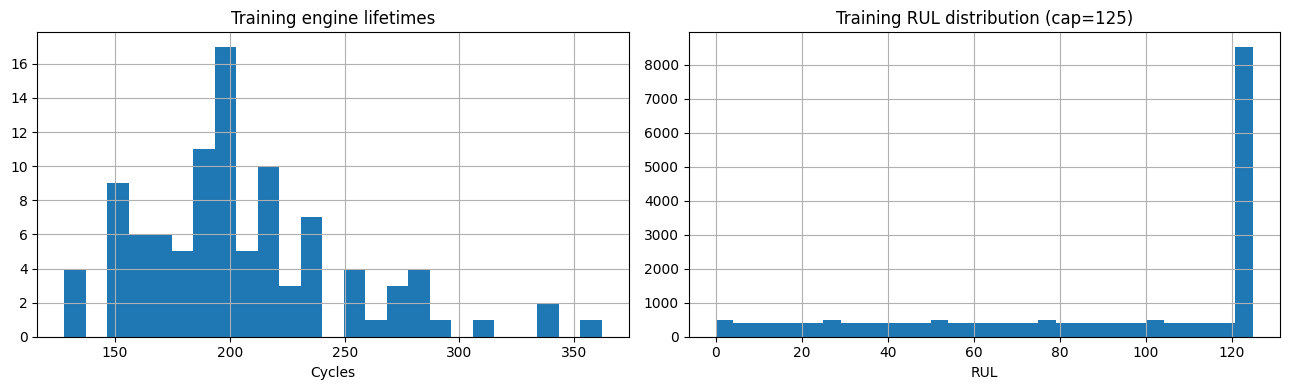

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

train_df.groupby("unit")["cycle"].max().hist(bins=25, ax=axes[0])
axes[0].set_title("Training engine lifetimes")
axes[0].set_xlabel("Cycles")

train_df["RUL"].hist(bins=30, ax=axes[1])
axes[1].set_title(f"Training RUL distribution (cap={RUL_CAP})")
axes[1].set_xlabel("RUL")

plt.tight_layout()
plt.show()


## 6. Feature selection — training engines only

The earlier V3 calculated feature variance on the complete training file before splitting engines. This is a small unsupervised leakage risk. Here, feature selection is fitted only on `train_part`.

Selected feature count: 17
Selected features: ['op_setting_1', 'op_setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Removed constant/near-constant features: ['op_setting_3', 'sensor_1', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'sensor_5']
Missing selected training values: 0


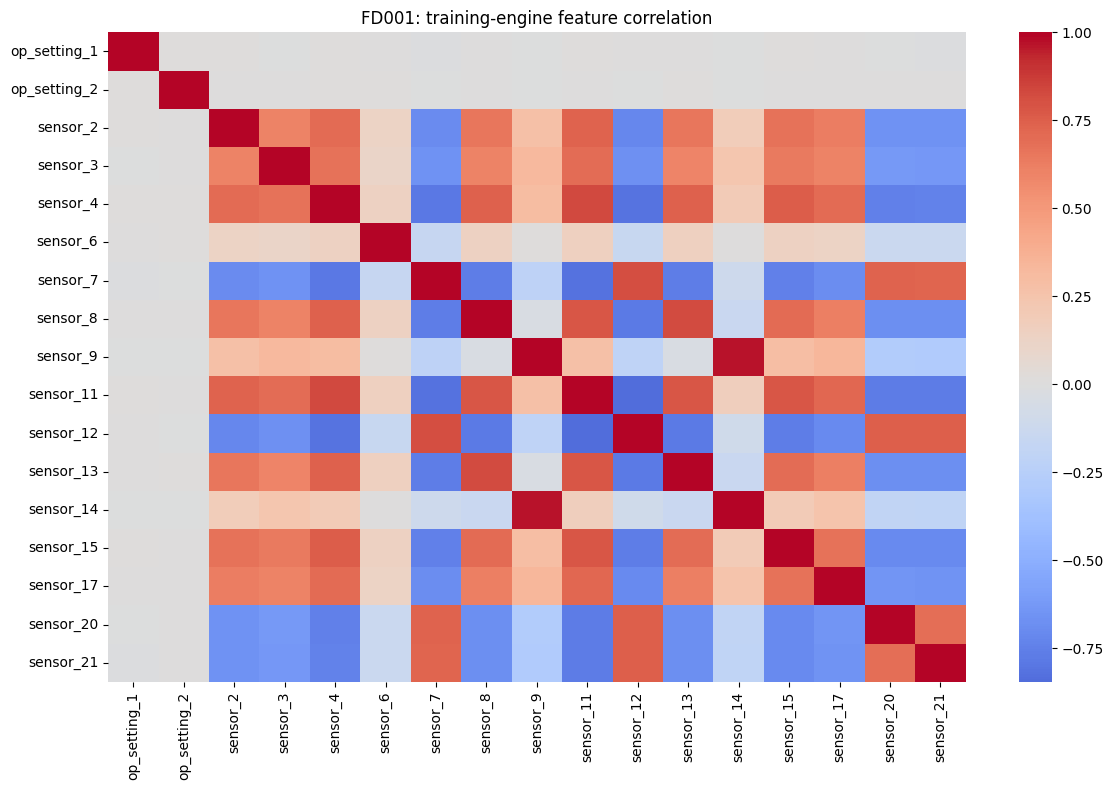

In [6]:
sensor_columns = [c for c in columns if c.startswith("sensor_")]
setting_columns = [c for c in columns if c.startswith("op_setting_")]

candidate_features = setting_columns + sensor_columns

feature_variance = train_part[candidate_features].var()
feature_columns = feature_variance[feature_variance > 1e-8].index.tolist()

removed_features = sorted(set(candidate_features) - set(feature_columns))

print("Selected feature count:", len(feature_columns))
print("Selected features:", feature_columns)
print("Removed constant/near-constant features:", removed_features)

missing_count = int(train_part[feature_columns].isna().sum().sum())
print("Missing selected training values:", missing_count)

plt.figure(figsize=(12, 8))
sns.heatmap(train_part[feature_columns].corr(), cmap="coolwarm", center=0)
plt.title(f"{SUBSET}: training-engine feature correlation")
plt.tight_layout()
plt.show()


## 7. Generate multiple validation cutoffs per engine

The previous V3 sampled one random cutoff per validation engine, and only from the later part of its lifetime. This version evaluates several RUL points per held-out engine. Each validation input still contains only observations available up to its cutoff.

In [7]:
val_records = []

for unit in val_units:
    engine = val_part[val_part["unit"] == unit].sort_values("cycle")
    final_cycle = int(engine["cycle"].max())

    for desired_rul in VALIDATION_RUL_POINTS:
        cutoff = final_cycle - int(desired_rul)
        prefix = engine[engine["cycle"] <= cutoff]

        # A valid sequence requires at least WINDOW_SIZE observed rows.
        if len(prefix) < WINDOW_SIZE:
            continue

        # Use the final observed row as the actual cutoff in case cycle IDs
        # contain gaps; this keeps the label aligned with the input window.
        observed_cutoff = int(prefix["cycle"].iloc[-1])

        val_records.append({
            "unit": int(unit),
            "cutoff_cycle": observed_cutoff,
            "actual_rul": float(final_cycle - observed_cutoff)
        })

val_meta = pd.DataFrame(val_records)

if val_meta.empty:
    raise ValueError(
        "No valid validation cutoffs. Reduce WINDOW_SIZE or revise "
        "VALIDATION_RUL_POINTS."
    )

print("Validation samples:", len(val_meta))
print("Validation engines represented:", val_meta["unit"].nunique())
display(val_meta.head(10))


Validation samples: 158
Validation engines represented: 20


,unit,cutoff_cycle,actual_rul
0,1,172,20.0
1,1,152,40.0
2,1,132,60.0
3,1,112,80.0
4,1,92,100.0
5,1,72,120.0
6,1,67,125.0
7,1,42,150.0
8,5,249,20.0
9,5,229,40.0


## 8. Fit imputer and scaler on unique training rows

Overlapping sliding windows repeat the same cycle many times. Fitting the scaler on flattened windows implicitly weights interior cycles more heavily than edge cycles. Instead, fit preprocessing once on unique training rows, then transform all sequences.

In [8]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

imputer.fit(train_part[feature_columns])
train_imputed = imputer.transform(train_part[feature_columns])
scaler.fit(train_imputed)

def transform_features(frame, feature_columns, imputer, scaler):
    transformed = frame.copy()
    values = imputer.transform(transformed[feature_columns])
    values = scaler.transform(values).astype(np.float32)

    # Assign each scaled feature as a new float column. In particular, `cycle`
    # is originally integer-typed, while its standardized values are floats.
    for index, column in enumerate(feature_columns):
        transformed[column] = values[:, index]

    return transformed

train_scaled_df = transform_features(train_df, feature_columns, imputer, scaler)
test_scaled_df = transform_features(test_df, feature_columns, imputer, scaler)

print("Preprocessing fitted on unique training rows:", train_part.shape[0])


Preprocessing fitted on unique training rows: 16561


## 9. Build training and validation sequences

In [9]:
def make_training_windows(data, units, features, window_size):
    X, y = [], []

    for unit in units:
        engine = data[data["unit"] == unit].sort_values("cycle")
        values = engine[features].to_numpy(dtype=np.float32)
        targets = engine["RUL"].to_numpy(dtype=np.float32)

        for end in range(window_size - 1, len(engine)):
            X.append(values[end - window_size + 1:end + 1])
            y.append(targets[end])

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


def make_validation_windows(data, metadata, features, window_size):
    X, y, rows = [], [], []

    for record in metadata.itertuples(index=False):
        engine_prefix = data[
            (data["unit"] == record.unit) &
            (data["cycle"] <= record.cutoff_cycle)
        ].sort_values("cycle")

        values = engine_prefix[features].to_numpy(dtype=np.float32)

        if len(values) < window_size:
            continue

        X.append(values[-window_size:])
        y.append(float(record.actual_rul))
        rows.append({
            "unit": int(record.unit),
            "cutoff_cycle": int(record.cutoff_cycle),
            "actual_rul": float(record.actual_rul)
        })

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.DataFrame(rows)
    )


X_train, y_train = make_training_windows(
    train_scaled_df, train_units, feature_columns, WINDOW_SIZE
)

X_val, y_val_actual, val_meta_used = make_validation_windows(
    train_scaled_df, val_meta, feature_columns, WINDOW_SIZE
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("Validation labels:", y_val_actual.shape)


if len(X_train) == 0:
    raise ValueError("No training windows were generated. Check WINDOW_SIZE and engine lengths.")
if len(X_val) == 0:
    raise ValueError("No validation windows were generated. Check validation cutoffs.")
if not (len(X_val) == len(y_val_actual) == len(val_meta_used)):
    raise RuntimeError("Validation windows, labels, and metadata are misaligned.")


X_train: (14241, 30, 17)
y_train: (14241,)
X_val: (158, 30, 17)
Validation labels: (158,)


## 10. Scale regression targets

In [10]:
y_mean = float(y_train.mean())
y_std = float(y_train.std() + 1e-8)

y_train_scaled = (y_train - y_mean) / y_std

print("Target mean:", y_mean)
print("Target std:", y_std)


Target mean: 80.81237030029297
Target std: 41.8094596862793


## 11. Evaluation metrics

In [11]:
def nasa_score(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.asarray(predicted, dtype=np.float64)

    error = predicted - actual
    penalties = np.where(
        error < 0,
        np.exp(-error / 13.0) - 1.0,
        np.exp(error / 10.0) - 1.0
    )
    return float(np.sum(penalties))


def evaluate_rul(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.maximum(np.asarray(predicted, dtype=np.float64), 0.0)

    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "NASA Score": nasa_score(actual, predicted),
        "Mean NASA Score": nasa_score(actual, predicted) / len(actual),
        "R2": float(r2_score(actual, predicted))
    }


## 12. Corrected classical baselines

**Important V3 flaw fixed here:** the old code selected the last row of every complete training engine. Since the training engines run to failure, every selected training row had RUL = 0. The models therefore learned a degenerate target. Here, RF/XGBoost train on all eligible training rows and are evaluated on the same held-out engine/cutoff rows as the BiLSTM.

In [12]:
# Training tabular baseline: all cycles from training engines.
X_tab_train = train_part[feature_columns]
y_tab_train = train_part["RUL"].to_numpy(dtype=np.float32)

# Validation tabular baseline: the observed row at each validation cutoff.
val_tab_rows = []
for record in val_meta_used.itertuples(index=False):
    row = val_part[
        (val_part["unit"] == record.unit) &
        (val_part["cycle"] == record.cutoff_cycle)
    ]
    if len(row) != 1:
        raise ValueError("Could not find exactly one row for a validation cutoff.")
    val_tab_rows.append(row.iloc[0])

val_tab_df = pd.DataFrame(val_tab_rows).reset_index(drop=True)
X_tab_val = val_tab_df[feature_columns]
y_tab_val_raw = val_meta_used["actual_rul"].to_numpy(dtype=np.float32)
y_tab_val_capped = np.minimum(y_tab_val_raw, RUL_CAP)

baseline_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=-1
    )
}

if XGBRegressor is not None:
    baseline_models["XGBoost"] = XGBRegressor(
        n_estimators=500,
        max_depth=5,
        learning_rate=0.03,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=-1
    )

baseline_results = []
baseline_raw_results = []
baseline_fitted = {}

for name, estimator in baseline_models.items():
    pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        estimator
    )
    pipeline.fit(X_tab_train, y_tab_train)
    predictions = np.maximum(pipeline.predict(X_tab_val), 0.0)
    capped_predictions = np.clip(predictions, 0.0, RUL_CAP)

    # Primary comparison uses the capped target convention used for training.
    capped_scores = evaluate_rul(y_tab_val_capped, capped_predictions)
    raw_scores = evaluate_rul(y_tab_val_raw, predictions)

    baseline_results.append({"Model": name, **capped_scores})
    baseline_raw_results.append({"Model": name, **raw_scores})
    baseline_fitted[name] = pipeline

print("Baseline metrics on capped validation RUL (primary comparison):")
baseline_results_df = pd.DataFrame(baseline_results)
display(baseline_results_df.round(3))

print("Baseline metrics on uncapped validation RUL (supplementary):")
baseline_raw_results_df = pd.DataFrame(baseline_raw_results)
display(baseline_raw_results_df.round(3))


Baseline metrics on capped validation RUL (primary comparison):


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,Random Forest,18.326,13.841,1247.757,7.897,0.767
1,XGBoost,18.333,13.883,1371.779,8.682,0.767


Baseline metrics on uncapped validation RUL (supplementary):


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,Random Forest,24.81,18.683,2387.178,15.109,0.696
1,XGBoost,25.04,18.731,2870.450,18.167,0.691


## 13. TCN architecture

A TCN processes the sequence with 1D convolutions. Dilations of 1, 2, and 4 let the network cover a wider temporal context without recurrent hidden states. Each block uses a residual connection so information and gradients can pass through the stack more easily.

The input shape is `(batch, time_steps, features)`. The network transposes it to `(batch, features, time_steps)` for `Conv1d`, then uses the representation at the final observed time step to predict RUL.


In [13]:
import torch.nn.functional as F

class CausalTemporalBlock(nn.Module):
    """Two causal dilated convolutions with a residual connection."""
    def __init__(self, in_channels, out_channels, kernel_size=3, dilation=1, dropout=0.15):
        super().__init__()
        self.padding = (kernel_size - 1) * dilation

        self.conv1 = nn.Conv1d(
            in_channels, out_channels,
            kernel_size=kernel_size,
            padding=self.padding,
            dilation=dilation
        )
        self.conv2 = nn.Conv1d(
            out_channels, out_channels,
            kernel_size=kernel_size,
            padding=self.padding,
            dilation=dilation
        )
        self.dropout = nn.Dropout(dropout)
        self.activation = nn.GELU()
        self.residual = (
            nn.Conv1d(in_channels, out_channels, kernel_size=1)
            if in_channels != out_channels else nn.Identity()
        )

    def _crop_future_padding(self, x, original_length):
        # Conv1d's symmetric padding adds positions to the right; remove them
        # so output at time t cannot depend on later time steps.
        return x[..., :original_length]

    def forward(self, x):
        original_length = x.size(-1)

        out = self.conv1(x)
        out = self._crop_future_padding(out, original_length)
        out = self.activation(out)
        out = self.dropout(out)

        out = self.conv2(out)
        out = self._crop_future_padding(out, original_length)
        out = self.activation(out)
        out = self.dropout(out)

        return self.activation(out + self.residual(x))


class TCNRegressor(nn.Module):
    """TCN regressor for a fixed-length multivariate sensor window."""
    def __init__(self, input_size, channels=64, kernel_size=3, dropout=0.15):
        super().__init__()
        self.input_projection = nn.Conv1d(input_size, channels, kernel_size=1)
        self.temporal_blocks = nn.Sequential(
            CausalTemporalBlock(channels, channels, kernel_size, dilation=1, dropout=dropout),
            CausalTemporalBlock(channels, channels, kernel_size, dilation=2, dropout=dropout),
            CausalTemporalBlock(channels, channels, kernel_size, dilation=4, dropout=dropout),
        )
        self.head = nn.Sequential(
            nn.LayerNorm(channels),
            nn.Linear(channels, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        # x: (batch, time, features) -> (batch, features, time)
        x = x.transpose(1, 2)
        x = self.input_projection(x)
        x = self.temporal_blocks(x)
        final_timestep = x[:, :, -1]
        return self.head(final_timestep).squeeze(1)


n_features = len(feature_columns)
model = TCNRegressor(
    input_size=n_features,
    channels=64,
    kernel_size=3,
    dropout=0.15
).to(device)

num_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters: {num_parameters:,}")

# Shape and gradient sanity check before the full training run.
_dummy = torch.zeros(4, WINDOW_SIZE, n_features, dtype=torch.float32, device=device)
_dummy_out = model(_dummy)
assert _dummy_out.shape == (4,), f"Unexpected output shape: {_dummy_out.shape}"
_dummy_out.mean().backward()
model.zero_grad(set_to_none=True)
print("Forward-pass and gradient checks passed.")
del _dummy, _dummy_out


TCNRegressor(
  (input_projection): Conv1d(17, 64, kernel_size=(1,), stride=(1,))
  (temporal_blocks): Sequential(
    (0): CausalTemporalBlock(
      (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(2,))
      (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(2,))
      (dropout): Dropout(p=0.15, inplace=False)
      (activation): GELU(approximate='none')
      (residual): Identity()
    )
    (1): CausalTemporalBlock(
      (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
      (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(4,), dilation=(2,))
      (dropout): Dropout(p=0.15, inplace=False)
      (activation): GELU(approximate='none')
      (residual): Identity()
    )
    (2): CausalTemporalBlock(
      (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(8,), dilation=(4,))
      (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(8,), dilation=(4,))
      (dropout): Dropout(p=0.

## 14. Train the TCN with early stopping

The target scaling, SmoothL1 loss, optimizer, learning-rate scheduler, gradient clipping, and capped-RUL checkpoint metric are kept aligned with the audited V3 procedure.


In [14]:
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train_scaled, dtype=torch.float32)
)

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=PIN_MEMORY,
    num_workers=0,
    generator=loader_generator
)

val_tensor = torch.tensor(X_val, dtype=torch.float32, device=device)
y_val_capped = np.minimum(y_val_actual, RUL_CAP)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=4
)
loss_fn = nn.SmoothL1Loss()

best_val_rmse = float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0
history = []

for epoch in range(1, MAX_EPOCHS + 1):
    lr_used = optimizer.param_groups[0]["lr"]
    model.train()
    running_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        predictions = model(batch_X)
        loss = loss_fn(predictions, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        optimizer.step()
        running_loss += loss.item() * len(batch_X)

    train_loss = running_loss / len(train_dataset)

    model.eval()
    with torch.no_grad():
        val_scaled_predictions = model(val_tensor).cpu().numpy()

    val_predictions_raw = np.maximum(val_scaled_predictions * y_std + y_mean, 0.0)
    val_predictions_capped = np.clip(val_predictions_raw, 0.0, RUL_CAP)
    val_rmse_capped = float(np.sqrt(mean_squared_error(y_val_capped, val_predictions_capped)))
    val_rmse_raw = float(np.sqrt(mean_squared_error(y_val_actual, val_predictions_raw)))

    scheduler.step(val_rmse_capped)
    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_rmse_capped": val_rmse_capped,
        "val_rmse_raw": val_rmse_raw,
        "lr_used": lr_used,
        "next_lr": optimizer.param_groups[0]["lr"]
    })

    if val_rmse_capped < best_val_rmse:
        best_val_rmse = val_rmse_capped
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val RMSE capped: {val_rmse_capped:.3f} | "
            f"Val RMSE raw: {val_rmse_raw:.3f} | "
            f"LR: {lr_used:.2e}"
        )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping. Best epoch: {best_epoch}")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid checkpoint.")

model.load_state_dict(best_state)
model.eval()
print("Best validation capped RMSE:", round(best_val_rmse, 3))


Epoch 001/80 | Train loss: 0.1194 | Val RMSE capped: 15.365 | Val RMSE raw: 23.085 | LR: 1.00e-03
Epoch 005/80 | Train loss: 0.0496 | Val RMSE capped: 15.457 | Val RMSE raw: 22.806 | LR: 1.00e-03
Epoch 010/80 | Train loss: 0.0277 | Val RMSE capped: 16.847 | Val RMSE raw: 23.323 | LR: 5.00e-04
Epoch 015/80 | Train loss: 0.0210 | Val RMSE capped: 17.398 | Val RMSE raw: 23.631 | LR: 2.50e-04
Early stopping. Best epoch: 4
Best validation capped RMSE: 14.433


## 15. Validation results and comparison

The primary metric is calculated on capped validation RUL because the training target is capped at 125. Raw-RUL metrics are supplementary and should not be mixed with capped metrics.


TCN validation metrics (raw RUL; supplementary):


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,21.691,15.379,1773.57,11.225,0.768


TCN validation metrics (capped RUL; primary):


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,14.433,10.537,755.657,4.783,0.855


Best epoch: 4


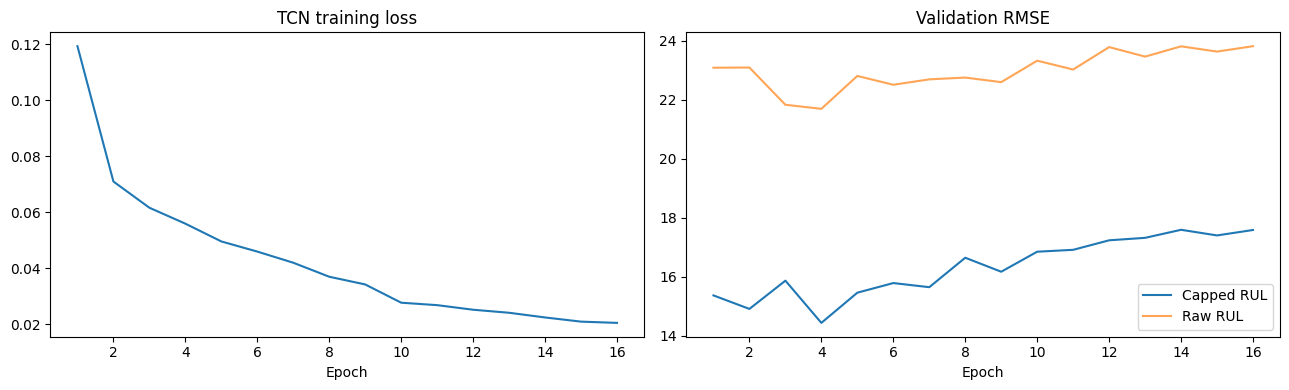

Capped-RUL validation comparison:


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,TCN,14.433,10.537,755.657,4.783,0.855
1,Random Forest,18.326,13.841,1247.757,7.897,0.767
2,XGBoost,18.333,13.883,1371.779,8.682,0.767


Raw-RUL validation comparison (supplementary):


,Model,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,TCN,21.691,15.379,1773.570,11.225,0.768
1,Random Forest,24.810,18.683,2387.178,15.109,0.696
2,XGBoost,25.040,18.731,2870.450,18.167,0.691


In [15]:
with torch.no_grad():
    val_scaled_predictions = model(val_tensor).cpu().numpy()

val_predictions = np.maximum(val_scaled_predictions * y_std + y_mean, 0.0)
val_predictions_capped = np.clip(val_predictions, 0.0, RUL_CAP)
y_val_capped = np.minimum(y_val_actual, RUL_CAP)

tcn_val_scores_raw = evaluate_rul(y_val_actual, val_predictions)
tcn_val_scores_capped = evaluate_rul(y_val_capped, val_predictions_capped)

print("TCN validation metrics (raw RUL; supplementary):")
display(pd.DataFrame([tcn_val_scores_raw]).round(3))
print("TCN validation metrics (capped RUL; primary):")
display(pd.DataFrame([tcn_val_scores_capped]).round(3))
print("Best epoch:", best_epoch)

history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"])
axes[0].set_title("TCN training loss")
axes[0].set_xlabel("Epoch")
axes[1].plot(history_df["epoch"], history_df["val_rmse_capped"], label="Capped RUL")
axes[1].plot(history_df["epoch"], history_df["val_rmse_raw"], label="Raw RUL", alpha=0.7)
axes[1].set_title("Validation RMSE")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

comparison_rows = baseline_results + [{"Model": "TCN", **tcn_val_scores_capped}]
validation_comparison = pd.DataFrame(comparison_rows).sort_values("RMSE").reset_index(drop=True)
print("Capped-RUL validation comparison:")
display(validation_comparison.round(3))

raw_comparison_rows = baseline_raw_results + [{"Model": "TCN", **tcn_val_scores_raw}]
validation_raw_comparison = pd.DataFrame(raw_comparison_rows).sort_values("RMSE").reset_index(drop=True)
print("Raw-RUL validation comparison (supplementary):")
display(validation_raw_comparison.round(3))


## 16. Validation error analysis


,unit,cutoff_cycle,actual_rul,predicted_RUL,error,absolute_error
115,74,106,60.0,111.209343,51.209343,51.209343
122,77,94,60.0,101.254700,41.254700,41.254700
83,45,78,80.0,117.741753,37.741753,37.741753
148,84,167,100.0,62.706947,-37.293053,37.293053
28,13,103,60.0,95.454010,35.454010,35.454010
3,1,112,80.0,115.130768,35.130768,35.130768
114,74,126,40.0,74.151505,34.151505,34.151505
123,77,74,80.0,114.020660,34.020660,34.020660
116,74,86,80.0,110.670410,30.670410,30.670410
49,31,174,60.0,90.530617,30.530617,30.530617


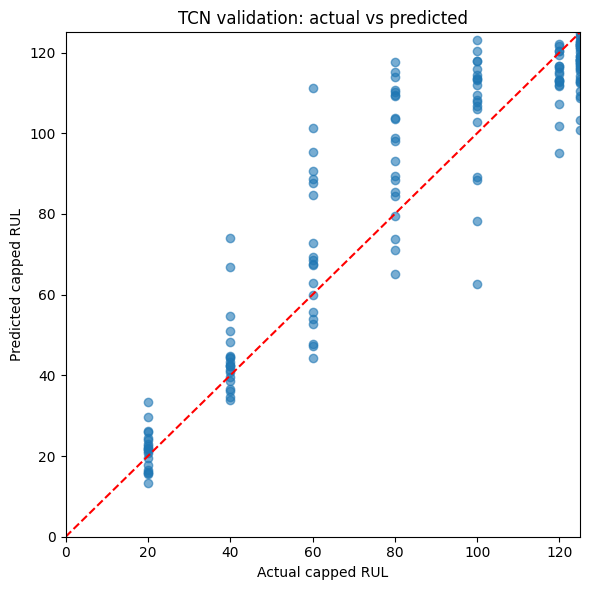

In [16]:
val_analysis = val_meta_used.copy()
val_analysis["predicted_RUL"] = val_predictions_capped
val_analysis["error"] = val_analysis["predicted_RUL"] - np.minimum(val_analysis["actual_rul"], RUL_CAP)
val_analysis["absolute_error"] = val_analysis["error"].abs()
display(val_analysis.sort_values("absolute_error", ascending=False).head(20))

plt.figure(figsize=(6, 6))
plt.scatter(np.minimum(y_val_actual, RUL_CAP), val_predictions_capped, alpha=0.6)
plt.plot([0, RUL_CAP], [0, RUL_CAP], "r--")
plt.xlim(0, RUL_CAP)
plt.ylim(0, RUL_CAP)
plt.xlabel("Actual capped RUL")
plt.ylabel("Predicted capped RUL")
plt.title("TCN validation: actual vs predicted")
plt.tight_layout()
plt.show()


## 17. Refit preprocessing and TCN on all official training engines

After model selection is complete, preprocessing is refitted on all official training rows. The TCN is reinitialized and trained on all valid windows, replaying the learning-rate schedule selected during validation.


In [17]:
final_imputer = SimpleImputer(strategy="median")
final_scaler = StandardScaler()
final_imputer.fit(train_df[feature_columns])
train_all_imputed = final_imputer.transform(train_df[feature_columns])
final_scaler.fit(train_all_imputed)

train_all_scaled_df = transform_features(train_df, feature_columns, final_imputer, final_scaler)
test_all_scaled_df = transform_features(test_df, feature_columns, final_imputer, final_scaler)

X_full, y_full = make_training_windows(
    train_all_scaled_df,
    train_all_scaled_df["unit"].unique(),
    feature_columns,
    WINDOW_SIZE
)

test_windows = []
for unit in test_units:
    engine = test_all_scaled_df[test_all_scaled_df["unit"] == unit].sort_values("cycle")
    values = engine[feature_columns].to_numpy(dtype=np.float32)
    if len(values) < WINDOW_SIZE:
        raise ValueError(f"Test engine {unit} has fewer than WINDOW_SIZE rows.")
    test_windows.append(values[-WINDOW_SIZE:])

X_test = np.asarray(test_windows, dtype=np.float32)
y_test_actual = np.asarray([test_rul_map[unit] for unit in test_units], dtype=np.float32)

final_y_mean = float(y_full.mean())
final_y_std = float(y_full.std() + 1e-8)
y_full_scaled = (y_full - final_y_mean) / final_y_std

seed_everything(SEED + 1)
final_model = TCNRegressor(
    input_size=len(feature_columns), channels=64, kernel_size=3, dropout=0.15
).to(device)

final_dataset = TensorDataset(
    torch.tensor(X_full, dtype=torch.float32),
    torch.tensor(y_full_scaled, dtype=torch.float32)
)
final_generator = torch.Generator()
final_generator.manual_seed(SEED)
final_loader = DataLoader(
    final_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=PIN_MEMORY,
    num_workers=0,
    generator=final_generator
)

final_optimizer = torch.optim.AdamW(final_model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
final_loss_fn = nn.SmoothL1Loss()
lr_schedule = [item["lr_used"] for item in history[:best_epoch]]

for epoch in range(best_epoch):
    for group in final_optimizer.param_groups:
        group["lr"] = lr_schedule[epoch]
    final_model.train()
    for batch_X, batch_y in final_loader:
        batch_X = batch_X.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)
        final_optimizer.zero_grad(set_to_none=True)
        predictions = final_model(batch_X)
        loss = final_loss_fn(predictions, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(final_model.parameters(), max_norm=GRAD_CLIP)
        final_optimizer.step()

final_model.eval()
print("Final training windows:", X_full.shape)
print("Official test windows:", X_test.shape)
print("Refit epochs:", best_epoch)


Final training windows: (17731, 30, 17)
Official test windows: (100, 30, 17)
Refit epochs: 4


## 18. Official test evaluation

Run this only after the architecture and training settings have been selected using validation data. Report both raw and capped targets; the capped metric matches the model's training target.


In [18]:
test_tensor = torch.tensor(X_test, dtype=torch.float32, device=device)
with torch.no_grad():
    test_scaled_predictions = final_model(test_tensor).cpu().numpy()

test_predictions_unclipped = np.maximum(test_scaled_predictions * final_y_std + final_y_mean, 0.0)
test_predictions = np.clip(test_predictions_unclipped, 0.0, RUL_CAP)
test_actual_capped = np.minimum(y_test_actual, RUL_CAP)

test_scores_raw = evaluate_rul(y_test_actual, test_predictions)
test_scores_capped = evaluate_rul(test_actual_capped, test_predictions)
print("Official test metrics against raw supplied RUL:")
display(pd.DataFrame([test_scores_raw]).round(3))
print("Official test metrics against capped supplied RUL:")
display(pd.DataFrame([test_scores_capped]).round(3))


Official test metrics against raw supplied RUL:


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,15.358,11.374,382.905,3.829,0.863


Official test metrics against capped supplied RUL:


,RMSE,MAE,NASA Score,Mean NASA Score,R2
0,14.168,10.304,348.203,3.482,0.875


## 19. Official test error analysis


,unit,actual_RUL,actual_RUL_capped,predicted_RUL,error_capped,absolute_error_capped
92,93,85.0,85.0,45.566784,-39.433216,39.433216
78,79,63.0,63.0,102.218651,39.218651,39.218651
66,67,77.0,77.0,116.137054,39.137054,39.137054
44,45,114.0,114.0,79.937737,-34.062263,34.062263
14,15,83.0,83.0,114.641388,31.641388,31.641388
26,27,66.0,66.0,97.306183,31.306183,31.306183
12,13,95.0,95.0,66.237427,-28.762573,28.762573
53,54,97.0,97.0,123.311264,26.311264,26.311264
59,60,100.0,100.0,123.927055,23.927055,23.927055
94,95,128.0,125.0,101.122940,-23.877060,23.877060


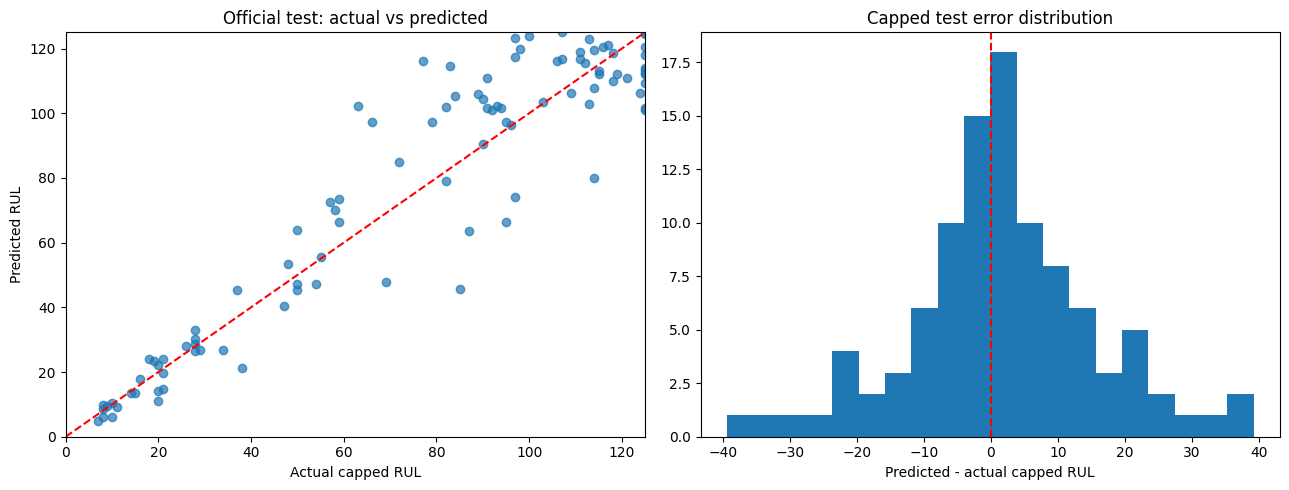

In [19]:
test_results = pd.DataFrame({
    "unit": test_units,
    "actual_RUL": y_test_actual,
    "actual_RUL_capped": np.minimum(y_test_actual, RUL_CAP),
    "predicted_RUL": test_predictions
})
test_results["error_capped"] = test_results["predicted_RUL"] - test_results["actual_RUL_capped"]
test_results["absolute_error_capped"] = test_results["error_capped"].abs()
display(test_results.sort_values("absolute_error_capped", ascending=False).head(20))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(test_results["actual_RUL_capped"], test_results["predicted_RUL"], alpha=0.7)
axes[0].plot([0, RUL_CAP], [0, RUL_CAP], "r--")
axes[0].set_xlim(0, RUL_CAP)
axes[0].set_ylim(0, RUL_CAP)
axes[0].set_xlabel("Actual capped RUL")
axes[0].set_ylabel("Predicted RUL")
axes[0].set_title("Official test: actual vs predicted")
axes[1].hist(test_results["error_capped"], bins=20)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted - actual capped RUL")
axes[1].set_title("Capped test error distribution")
plt.tight_layout()
plt.show()


## 20. Save artifacts


In [20]:
checkpoint_path = OUTPUT_DIR / "tcn_cmapss_fd001.pt"
preprocess_path = OUTPUT_DIR / "tcn_preprocessing.joblib"
metadata_path = OUTPUT_DIR / "tcn_metadata.json"
results_path = OUTPUT_DIR / "tcn_test_predictions.csv"

torch.save({
    "model_state_dict": final_model.state_dict(),
    "model_name": "TCNRegressor",
    "input_size": len(feature_columns),
    "channels": 64,
    "kernel_size": 3,
    "dilations": [1, 2, 4],
    "dropout": 0.15,
    "window_size": WINDOW_SIZE,
    "feature_columns": feature_columns,
    "rul_cap": RUL_CAP,
    "subset": SUBSET
}, checkpoint_path)

joblib.dump({
    "imputer": final_imputer,
    "scaler": final_scaler,
    "target_mean": final_y_mean,
    "target_std": final_y_std,
    "feature_columns": feature_columns
}, preprocess_path)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump({
        "subset": SUBSET,
        "model": "TCNRegressor",
        "window_size": WINDOW_SIZE,
        "rul_cap": RUL_CAP,
        "best_validation_epoch": best_epoch,
        "validation_metrics_raw_rul": tcn_val_scores_raw,
        "validation_metrics_capped_rul": tcn_val_scores_capped,
        "official_test_metrics_raw_rul": test_scores_raw,
        "official_test_metrics_capped_rul": test_scores_capped,
        "num_parameters": num_parameters,
        "validation_cutoff_rul_points": VALIDATION_RUL_POINTS
    }, f, indent=2)

test_results.to_csv(results_path, index=False)
print("Saved artifacts:")
print(checkpoint_path)
print(preprocess_path)
print(metadata_path)
print(results_path)


Saved artifacts:
artifacts\FD001_V3_audited\tcn_cmapss_fd001.pt
artifacts\FD001_V3_audited\tcn_preprocessing.joblib
artifacts\FD001_V3_audited\tcn_metadata.json
artifacts\FD001_V3_audited\tcn_test_predictions.csv


## 21. How to interpret the experiment

- Compare the TCN with Random Forest and XGBoost using the **same capped validation target**.
- Compare its official test RMSE/MAE/NASA score with earlier models only when the target convention is identical.
- Do not use official test metrics to tune architecture or hyperparameters.
- If TCN training RMSE falls while validation RMSE stays high, it is overfitting. Reduce channels/dropout or increase weight decay before making the network larger.
- Repeat with multiple seeds before claiming that one model is better. FD001 has relatively few independent engines, so one split can be noisy.

The notebook does not promise that TCN will beat BiLSTM. It is a controlled alternative to test, not a guaranteed improvement.
